In [9]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# API key
API_KEY = "614ea74aaccc70cc2137fc363f1daa98"

# Cities
cities = ["Pune", "Mumbai", "Delhi", "Bangalore", "Chennai"]

weather_list = []

# Fetch data
for city in cities:

    url = f"https://api.openweathermap.org/data/2.5/weather?q={city}&appid={API_KEY}&units=metric"

    response = requests.get(url)

    if response.status_code == 200:

        data = response.json()

        weather_list.append({
            "City": city,
            "Temperature": data["main"]["temp"],
            "Humidity": data["main"]["humidity"],
            "Wind_Speed": data["wind"]["speed"],
            "Precipitation": data.get("rain", {}).get("1h", 0),
            "Latitude": data["coord"]["lat"],
            "Longitude": data["coord"]["lon"]
        })

    else:
        print("Error retrieving data for", city)


In [11]:

# Create DataFrame
df = pd.DataFrame(weather_list)

# Cleaning
df.fillna(0, inplace=True)

print("\nWeather Data:")
print(df)



Weather Data:
        City  Temperature  Humidity  Wind_Speed  Precipitation  Latitude  \
0       Pune        24.26        89        3.82           0.00   18.5196   
1     Mumbai        28.99        79        3.09           1.19   19.0144   
2      Delhi        31.96        70        2.57           0.00   28.6667   
3  Bangalore        27.42        68        1.03           0.25   12.9762   
4    Chennai        30.73        79        3.09           0.00   13.0878   

   Longitude  
0    73.8553  
1    72.8479  
2    77.2167  
3    77.6033  
4    80.2785  


In [12]:
# Statistics
print("\nAverage Temperature:", df["Temperature"].mean())
print("Maximum Temperature:", df["Temperature"].max())
print("Minimum Temperature:", df["Temperature"].min())

print("\nAverage Humidity:", df["Humidity"].mean())
print("Average Wind Speed:", df["Wind_Speed"].mean())



Average Temperature: 28.672000000000004
Maximum Temperature: 31.96
Minimum Temperature: 24.26

Average Humidity: 77.0
Average Wind Speed: 2.7199999999999998


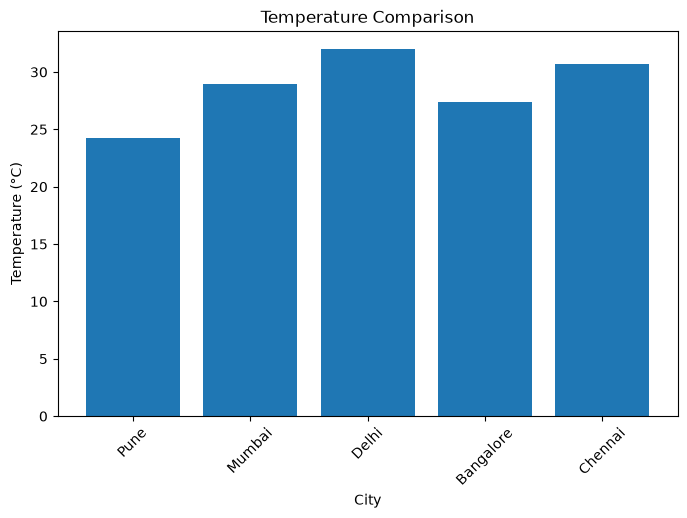

In [13]:
# Temperature visualization
plt.figure(figsize=(8,5))
plt.bar(df["City"], df["Temperature"])
plt.xlabel("City")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Comparison")
plt.xticks(rotation=45)
plt.show()

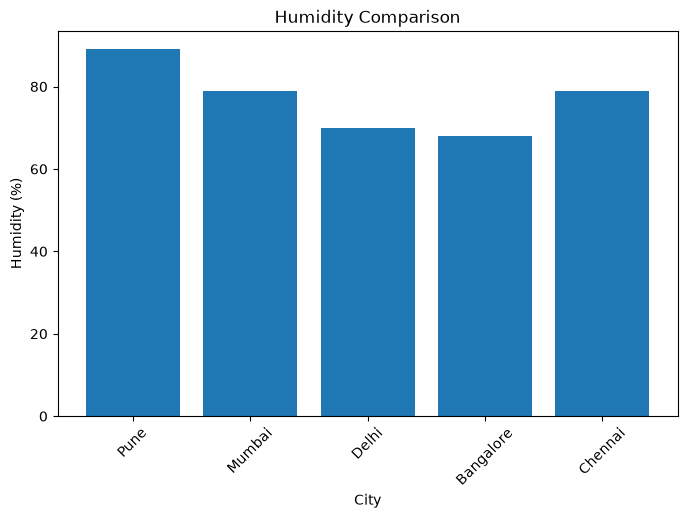

In [14]:
# Humidity visualization
plt.figure(figsize=(8,5))
plt.bar(df["City"], df["Humidity"])
plt.xlabel("City")
plt.ylabel("Humidity (%)")
plt.title("Humidity Comparison")
plt.xticks(rotation=45)
plt.show()


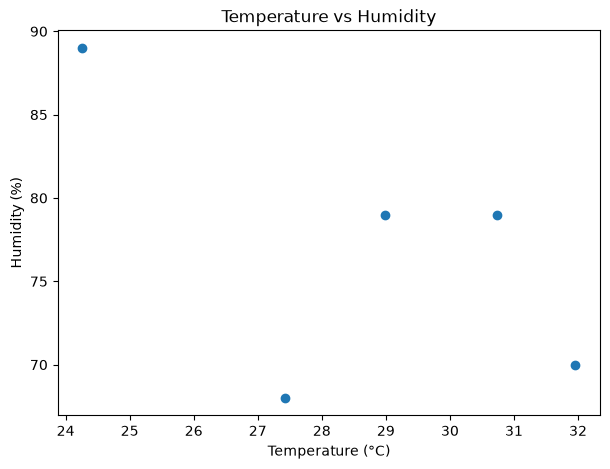

In [15]:
# Temperature vs Humidity
plt.figure(figsize=(7,5))
plt.scatter(df["Temperature"], df["Humidity"])
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.title("Temperature vs Humidity")
plt.show()

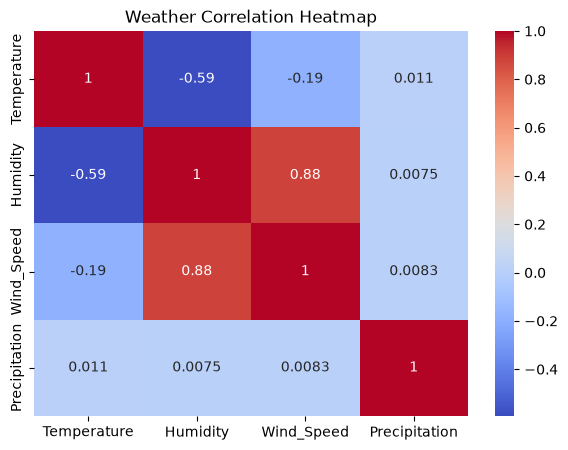

In [17]:
# Correlation
corr = df[
    ["Temperature", "Humidity", "Wind_Speed", "Precipitation"]
].corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Weather Correlation Heatmap")
plt.show()



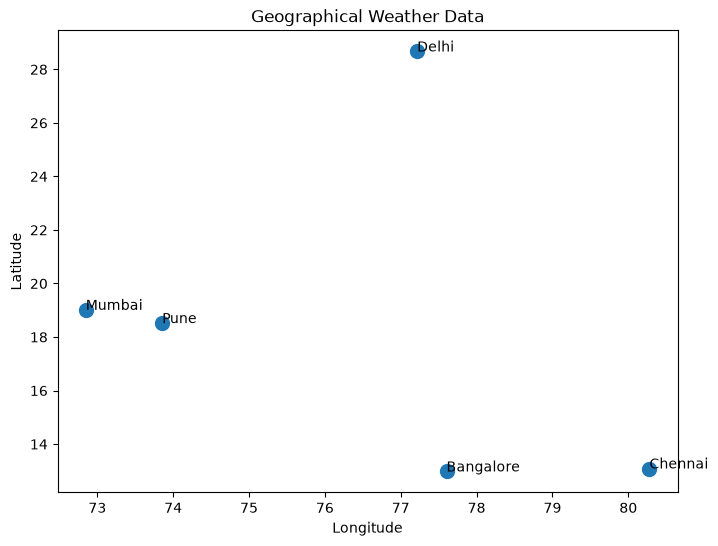

In [18]:
# Geographic visualization
plt.figure(figsize=(8,6))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    s=100
)

for i in range(len(df)):
    plt.text(
        df["Longitude"][i],
        df["Latitude"][i],
        df["City"][i]
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Weather Data")

plt.show()